# Misión 4 · Del dato al proceso
Python toma el control · AI Customer Intelligence

Trabaja desde la carpeta `proyecto`. Alterna conductor y revisor en cada reto.
Reinicia el kernel y ejecuta todas las celdas antes de entregar.
Los datos de este kit son sintéticos; no entrenamos un modelo en esta misión.

In [1]:
from pathlib import Path
import pandas as pd
BASE = Path.cwd()
assert (BASE / 'datos').exists(), 'Abre Jupyter desde la carpeta proyecto'

## Reto 1 · El inspector de clientes (25 minutos)
Completa `validaciones.py`. Devuelve todos los errores y conserva el diccionario original.
1. id_cliente existe y no es None.
2. antiguedad_meses no es negativa.
3. abandono pertenece a 0 o 1.
En este primer reto los dos últimos campos existen y son enteros.
Recorre la lista con un bucle y cuenta clientes con errores (no mensajes).
Mueve la función a un módulo e impórtala; reinicia el kernel al editarlo.

In [2]:
from validaciones import validar_cliente

# Pruebas mínimas del inspector
print("Cliente válido:", validar_cliente({"id_cliente": 101, "antiguedad_meses": 12, "abandono": 0}))
print("Antigüedad negativa:", validar_cliente({"id_cliente": 102, "antiguedad_meses": -3, "abandono": 1}))
print("Sin id:", validar_cliente({"antiguedad_meses": 5, "abandono": 0}))

cliente_104 = {"id_cliente": 104, "antiguedad_meses": -3, "abandono": 2}
print("Cliente 104:", validar_cliente(cliente_104))
print("Cliente 104 sin modificar:", cliente_104)  # Verifica que la función no altera el dato original

# Validación de una lista de clientes y recuento de clientes con incidencias
clientes = [
    {"id_cliente": 101, "antiguedad_meses": 12, "abandono": 0},
    {"id_cliente": 102, "antiguedad_meses": -3, "abandono": 2},
    {"id_cliente": 103, "antiguedad_meses": 8, "abandono": 1},
]

contador = 0  # Se inicializa antes del bucle
for cliente in clientes:
    errores = validar_cliente(cliente)
    if errores:
        contador += 1  # Cuenta clientes con incidencias, no mensajes de error
        print(cliente["id_cliente"], errores)
    else:
        print(cliente["id_cliente"], "OK")

print("Clientes con errores:", contador)  # Resumen fuera del bucle

Cliente válido: []
Antigüedad negativa: ['Antigüedad negativa']
Sin id: ['Falta id_cliente']
Cliente 104: ['Antigüedad negativa', 'Abandono debe ser 0 o 1']
Cliente 104 sin modificar: {'id_cliente': 104, 'antiguedad_meses': -3, 'abandono': 2}
101 OK
102 ['Antigüedad negativa', 'Abandono debe ser 0 o 1']
103 OK
Clientes con errores: 1


## Reto 2 · Abre el puente (30 minutos)
Copia `.env.example` como `.env`; configura tus credenciales.
Conecta con `mysql.connector`, cuenta clientes y recupera los cinco primeros.
Compara con Workbench. Cierra recursos incluso cuando falle una consulta.
Prueba un DB_NAME inexistente y documenta el diagnóstico. Restaura `.env` y reinicia
el kernel: `load_dotenv` no sustituye por defecto variables ya cargadas.
Nunca incluyas credenciales en capturas ni en la entrega.

In [3]:
import os
from dotenv import load_dotenv
import mysql.connector

# Carga de la configuración de conexión desde .env (sin credenciales en el código)
load_dotenv(".env")
config = {
    "host": os.environ["DB_HOST"],
    "port": int(os.environ["DB_PORT"]),
    "user": os.environ["DB_USER"],
    "password": os.environ["DB_PASSWORD"],
    "database": os.environ["DB_NAME"],
}

conexion = None
cursor = None
try:
    # Apertura de la conexión y del cursor
    conexion = mysql.connector.connect(**config)
    cursor = conexion.cursor()

    # Consulta 1: recuento total de clientes (fetchone devuelve una única fila)
    cursor.execute("SELECT COUNT(*) FROM clientes")
    total = cursor.fetchone()[0]
    print("Base de datos:", os.environ["DB_NAME"])
    print("Clientes:", total)

    # Consulta 2: primeros cinco registros ordenados por id (fetchall devuelve todas las filas)
    cursor.execute("""
        SELECT id_cliente, nombre, antiguedad_meses
        FROM clientes
        ORDER BY id_cliente
        LIMIT 5
    """)
    for fila in cursor.fetchall():
        print(fila)

except mysql.connector.Error as error:
    # Diagnóstico del error de MySQL sin exponer la configuración ni la contraseña
    print("Error de MySQL:", error.errno, "-", error.msg)

finally:
    # Liberación de recursos garantizada, incluso si la conexión o la consulta fallan
    if cursor is not None:
        cursor.close()
    if conexion is not None:
        conexion.close()
    print("Cursor y conexión cerrados")

Base de datos: ai_customer
Clientes: 30
(1, 'Cliente 01', 1)
(2, 'Cliente 02', 31)
(3, 'Cliente 03', 8)
(4, 'Cliente 04', 26)
(5, 'Cliente 05', 10)
Cursor y conexión cerrados


## Reto 3 · Recupera el dataset (30 minutos)
Escribe tu SQL en `consulta_dataset.sql`. Debe preservar clientes sin operaciones.
Recupera todas las filas y cursor.description; construye el DataFrame con los nombres SQL.
Revisa shape, info e isna. Comprueba ids únicos y cobertura frente a la tabla clientes.
Antes de agregar, detecta `importe IS NULL` en operaciones: no equivale a cero.
El CSV tendrá exactamente las seis columnas acordadas.

In [4]:
import os
from pathlib import Path
import pandas as pd
import mysql.connector
from dotenv import load_dotenv

# Configuración de conexión desde .env
load_dotenv(".env")
config = {
    "host": os.environ["DB_HOST"],
    "port": int(os.environ["DB_PORT"]),
    "user": os.environ["DB_USER"],
    "password": os.environ["DB_PASSWORD"],
    "database": os.environ["DB_NAME"],
}

# Lectura de la consulta de extracción desde archivo
consulta = Path("consulta_dataset.sql").read_text(encoding="utf-8").strip().rstrip(";")

conexion = None
cursor = None
try:
    conexion = mysql.connector.connect(**config)
    cursor = conexion.cursor()

    # Control previo a la agregación: SUM y AVG ignoran NULL y podrían ocultar importes desconocidos
    cursor.execute("SELECT COUNT(*) FROM operaciones WHERE importe IS NULL")
    importes_nulos = cursor.fetchone()[0]
    print("Operaciones con importe NULL:", importes_nulos)

    # Ids de referencia de la tabla clientes, para verificar la cobertura
    cursor.execute("SELECT id_cliente FROM clientes")
    ids_clientes = {fila[0] for fila in cursor.fetchall()}

    # Extracción del dataset: filas + nombres de columnas obtenidos del cursor
    cursor.execute(consulta)
    filas = cursor.fetchall()
    columnas = [dato[0] for dato in cursor.description]
    df = pd.DataFrame(filas, columns=columnas)

finally:
    if cursor is not None:
        cursor.close()
    if conexion is not None:
        conexion.close()
    print("Cursor y conexión cerrados\n")

# Inspección del DataFrame
print("Columnas:", df.columns.tolist())
print("Dimensiones (filas, columnas):", df.shape)
df.info()
print("\nValores ausentes por columna:")
print(df.isna().sum())

# Comprobaciones de granularidad y cobertura (una fila por cliente)
print("\nid_cliente único:", df["id_cliente"].is_unique)
print("id_cliente ausentes:", df["id_cliente"].isna().sum())
print("Filas del dataset:", len(df), "| Clientes en la tabla:", len(ids_clientes))
print("Mismo conjunto de ids que la tabla clientes:", set(df["id_cliente"]) == ids_clientes)

# Clientes sin operaciones conservados por el LEFT JOIN
print("\nClientes sin operaciones:")
print(df[df["num_operaciones"] == 0])

df.head()

Operaciones con importe NULL: 0
Cursor y conexión cerrados

Columnas: ['id_cliente', 'antiguedad_meses', 'num_operaciones', 'gasto_total', 'ticket_medio', 'abandono']
Dimensiones (filas, columnas): (30, 6)
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   id_cliente        30 non-null     int64 
 1   antiguedad_meses  30 non-null     int64 
 2   num_operaciones   30 non-null     int64 
 3   gasto_total       30 non-null     object
 4   ticket_medio      30 non-null     object
 5   abandono          30 non-null     int64 
dtypes: int64(4), object(2)
memory usage: 1.5+ KB

Valores ausentes por columna:
id_cliente          0
antiguedad_meses    0
num_operaciones     0
gasto_total         0
ticket_medio        0
abandono            0
dtype: int64

id_cliente único: True
id_cliente ausentes: 0
Filas del dataset: 30 | Clientes en la tabla: 30
Mismo conjunt

,id_cliente,antiguedad_meses,num_operaciones,gasto_total,ticket_medio,abandono
0,1,1,4,874.16,218.540000,1
1,2,31,2,525.01,262.505000,0
2,3,8,6,1136.78,189.463333,0
3,4,26,6,1155.73,192.621667,0
4,5,10,1,120.59,120.590000,0


### Respaldo si MySQL bloquea la sesión
Puedes practicar pandas con el siguiente CSV. Identifica el origen en tus evidencias.
Este respaldo no acredita el reto de conexión a MySQL.

In [5]:
df_referencia = pd.read_csv(BASE / 'datos/dataset_referencia.csv')
df_referencia.head()

,id_cliente,antiguedad_meses,num_operaciones,gasto_total,ticket_medio,abandono
0,101,12,3,180,60,0
1,102,4,1,30,30,1
2,103,24,2,240,120,0
3,104,2,0,0,0,1
4,105,36,4,400,100,0


## Reto 4 · Control de calidad (30 minutos)
Trabaja sobre una copia. Completa `validar_dataset` y registra campo, regla, filas y acción.
Revisa estructura, faltantes, duplicados, tipos numéricos finitos, enteros donde procede,
rangos y abandono 0/1. Comprueba cobertura si conoces los ids esperados.
No elimines duplicados ni rellenes faltantes con cero sin evidencia.
La copia con incidencias debe bloquear la exportación; el informe debe guardarse.

In [6]:
import json
from validaciones import validar_dataset

# Prueba 1: dataset extraído de MySQL en el Reto 3 (debe superar la validación)
informe_mysql = validar_dataset(df, ids_esperados=ids_clientes)
print("Dataset MySQL -> válido:", informe_mysql["valido"],
      "| incidencias:", informe_mysql["num_incidencias"])

# Prueba 2: copia de práctica con errores introducidos (debe bloquear la exportación)
df_prueba = pd.read_csv(BASE / "datos/dataset_con_incidencias.csv")
ids_referencia = set(pd.read_csv(BASE / "datos/dataset_referencia.csv")["id_cliente"])
copia = df_prueba.copy()  # Se trabaja sobre una copia; el archivo original no se modifica
informe_prueba = validar_dataset(copia, ids_esperados=ids_referencia)

print("\nDataset de práctica -> válido:", informe_prueba["valido"])
print("Filas antes:", len(df_prueba), "| filas después:", len(copia),
      "(no se eliminan duplicados ni se rellenan ausentes)")
print("Incidencias:", informe_prueba["num_incidencias"],
      "| filas afectadas (posiciones):", informe_prueba["filas_afectadas"])

# El informe se guarda aunque la validación falle
ruta_informe = BASE / "salidas" / "reto4_informe_practica.json"
ruta_informe.parent.mkdir(exist_ok=True)
ruta_informe.write_text(json.dumps(informe_prueba, ensure_ascii=False, indent=2), encoding="utf-8")
print("Informe guardado en:", ruta_informe.relative_to(BASE))

# Bloqueo de la exportación ante errores críticos
if informe_prueba["valido"]:
    print("Exportación permitida")
else:
    print("Exportación BLOQUEADA: no se genera CSV")

# Tabla de incidencias (para la plantilla de evidencias)
pd.set_option("display.max_colwidth", None)
pd.DataFrame(informe_prueba["incidencias"])[["campo", "regla", "filas", "ids", "evidencia", "accion"]]

Dataset MySQL -> válido: True | incidencias: 0

Dataset de práctica -> válido: False
Filas antes: 13 | filas después: 13 (no se eliminan duplicados ni se rellenan ausentes)
Incidencias: 9 | filas afectadas (posiciones): [0, 1, 2, 3, 4, 5, 7, 8, 12]
Informe guardado en: salidas\reto4_informe_practica.json
Exportación BLOQUEADA: no se genera CSV


,campo,regla,filas,ids,evidencia,accion
0,id_cliente,Valor ausente en campo obligatorio,[3],[None],[None],Detener: revisar en origen; no rellenar con 0
1,antiguedad_meses,Debe ser un número entero,[8],[109],[2.5],Rechazar: revisar en origen
2,antiguedad_meses,No puede ser negativo,[1],[102],[-4],Rechazar: revisar en origen
3,num_operaciones,Debe ser un número entero,[5],[106],[1.5],Rechazar: revisar en origen
4,gasto_total,Valor ausente en campo obligatorio,[4],[105],[None],Detener: revisar en origen; no rellenar con 0
5,gasto_total,Valor no numérico,[7],[108],[error],Detener: corregir en origen
6,abandono,Abandono debe ser 0 o 1,[2],[103],[2],Rechazar: etiqueta no válida
7,id_cliente,id_cliente duplicado (una fila por cliente),"[0, 12]","[101, 101]","[101, 101]",Detener: revisar JOIN/GROUP BY; no usar drop_duplicates
8,id_cliente,Cobertura: faltan clientes de la referencia,[],[104],[],Detener: revisar LEFT JOIN y filtros


## Microreto · Pandas y matplotlib (20 minutos)
Sobre los datos válidos: selecciona columnas, filtra gasto_total > 100 y ordena de mayor a menor.
Añade sin_operaciones en una copia de análisis; conserva el esquema de seis columnas al exportar.
Resume gasto por abandono con count, mean y median. Representa gasto medio, con título,
ejes y unidad (euros en la demo). Si falta un grupo, dilo: su media no es cero.
Escribe una observación y una limitación: la diferencia no demuestra causalidad.

Clientes con gasto_total > 100: 26 de 30
 id_cliente  gasto_total
         18      1543.91
          4      1155.73
          3      1136.78
         27      1076.01
         15       987.05
         11       940.70
         29       901.24
         10       886.69
          1       874.16
         23       831.87
          9       808.12
         30       786.78
         22       660.29
         24       618.75
          8       586.81
          2       525.01
         25       461.58
         16       410.14
         13       320.27
          6       304.23
         20       298.11
         26       262.56
         19       244.78
         12       211.58
         17       170.12
          5       120.59

Clientes sin operaciones: 4
abandono          0  1
sin_operaciones       
False            21  5
True              0  4

Resumen de gasto_total por abandono:
          count    mean  median
abandono                       
0            21  624.49  525.01
1             9  445.51  586.

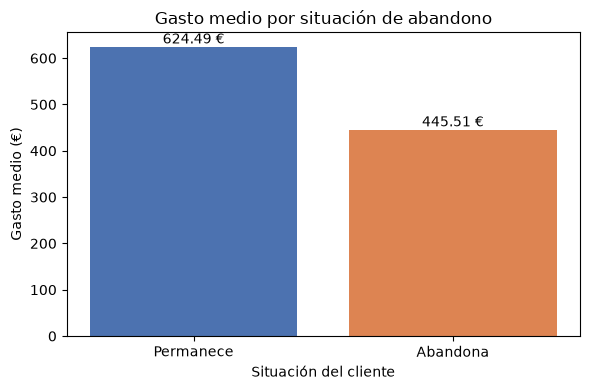

In [8]:
import matplotlib.pyplot as plt

# Copia de análisis: los importes DECIMAL de MySQL se convierten a float para analizar
analisis = df.copy()
analisis[["gasto_total", "ticket_medio"]] = analisis[["gasto_total", "ticket_medio"]].astype(float)

# 1. Selección y filtro: clientes con gasto_total > 100, de mayor a menor
mayores_100 = (
    analisis.loc[analisis["gasto_total"] > 100, ["id_cliente", "gasto_total"]]
    .sort_values("gasto_total", ascending=False)
)
print(f"Clientes con gasto_total > 100: {len(mayores_100)} de {len(analisis)}")
print(mayores_100.to_string(index=False))

# 2. Columna derivada en la copia de análisis (el dataset de 6 columnas no se modifica)
analisis["sin_operaciones"] = analisis["num_operaciones"] == 0
print("\nClientes sin operaciones:", int(analisis["sin_operaciones"].sum()))
print(pd.crosstab(analisis["sin_operaciones"], analisis["abandono"]))

# 3. Resumen del gasto por abandono: tamaño del grupo, media y mediana
resumen = analisis.groupby("abandono")["gasto_total"].agg(["count", "mean", "median"]).round(2)
print("\nResumen de gasto_total por abandono:")
print(resumen)
grupos_ausentes = {0, 1} - set(resumen.index)
if grupos_ausentes:
    print("Grupos sin datos (no se representan como cero):", grupos_ausentes)

# 4. Gráfico: gasto medio por situación del cliente
medias = resumen["mean"].rename(index={0: "Permanece", 1: "Abandona"})
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(medias.index, medias.values, color=["#4C72B0", "#DD8452"])
for posicion, valor in enumerate(medias.values):
    ax.text(posicion, valor, f"{valor:.2f} €", ha="center", va="bottom")
ax.set_title("Gasto medio por situación de abandono")
ax.set_xlabel("Situación del cliente")
ax.set_ylabel("Gasto medio (€)")
fig.tight_layout()

ruta_grafico = BASE / "salidas" / "gasto_por_abandono_notebook.png"
ruta_grafico.parent.mkdir(exist_ok=True)
fig.savefig(ruta_grafico, dpi=150)
print("\nGráfico guardado en:", ruta_grafico.relative_to(BASE))
plt.show()

## Reto final · Una ejecución, un dataset (30 minutos)
Completa `pipeline.py`: extraer, validar, guardar informe, exportar y generar gráfico.
Una carpeta por ejecución evita confundir resultados antiguos con una ejecución fallida.
CSV/PNG solo si la validación pasa; informe también si falla.
Ejecuta desde una terminal nueva, sin depender de variables del notebook.

## Evidencias y defensa (15 minutos)
Completa `../Plantilla_evidencias.md` y el README. Entrega notebook, módulos, SQL,
CSV, informe JSON, gráfico, `.env.example`, `.gitignore` y requirements.
Excluye `.env` y claves. Cada integrante explica una decisión y modifica una regla.
Declara la ayuda de IA recibida y cómo verificaste su resultado.